# MyDeZero GPU Optimization

## Fused FP32 Adam

The standard CUDA Adam path launches separate array operations for the moments,
bias correction, and weight update. This adds launch overhead and intermediate
reads and writes. MyDeZero's fused update uses one CuPy CUDA kernel per eligible
parameter tensor to update the weights and both moments in place. It keeps the
existing bias correction and uses the standard path for unsupported layouts,
dtypes, or overlapping buffers. `Adam(fused=False)` selects the reference path.

Install MyDeZero and use a kernel with CuPy and a CUDA device. See the
[CuPy setup guide](../../doc/cupy-setup.md). This experiment uses synthetic data.

In [1]:
import platform
from statistics import median
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np

from mydezero import Model, cuda
import mydezero.functions as F
import mydezero.layers as L
from mydezero.optimizers import Adam

BATCHES = (1, 16, 64)
ROUNDS = 7
CALLS_PER_ROUND = 15
BATCH_SIZE = max(BATCHES)
rng = np.random.default_rng(42)
inputs = rng.standard_normal((BATCH_SIZE, 64), dtype=np.float32)
labels = rng.integers(0, 8, BATCH_SIZE, dtype=np.int64)
shapes = ((64, 128), (128, 128), (128, 128), (128, 8))
weights = [rng.standard_normal(shape, dtype=np.float32) * np.float32(0.1) for shape in shapes]

print(f"{platform.system()} / Python {platform.python_version()} / NumPy {np.__version__}")
if not cuda.gpu_enable or cuda.cupy.cuda.runtime.getDeviceCount() == 0:
    raise RuntimeError('Run this notebook in a kernel with CuPy and a CUDA device.')
cp = cuda.cupy
device = cp.cuda.runtime.getDeviceProperties(cp.cuda.Device().id)['name'].decode()
print(f'{device} / CuPy {cp.__version__}')

Windows / Python 3.12.16 / NumPy 1.26.4
NVIDIA GeForce RTX 5060 Laptop GPU / CuPy 13.6.0


In [2]:
class MLP(Model):
    def __init__(self, xp):
        super().__init__()
        self.fc1 = L.Linear(128, in_size=64)
        self.fc2 = L.Linear(128, in_size=128)
        self.fc3 = L.Linear(128, in_size=128)
        self.fc4 = L.Linear(8, in_size=128)
        for layer, weight in zip((self.fc1, self.fc2, self.fc3, self.fc4), weights):
            layer.W.data = xp.asarray(weight).copy()
            layer.b.data = xp.zeros(weight.shape[1], dtype=xp.float32)

    def forward(self, x):
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = F.relu(self.fc3(x))
        return self.fc4(x)

    def ordered_parameters(self):
        return [param for layer in (self.fc1, self.fc2, self.fc3, self.fc4)
                for param in (layer.W, layer.b)]


def make_trial(xp, fused):
    model = MLP(xp)
    return model, Adam(lr=0.003, fused=fused).setup(model)


def step(trial, x, y):
    model, optimizer = trial
    model.cleargrads()
    loss = F.softmax_cross_entropy(model(x), y)
    loss.backward()
    optimizer.update()
    return loss.data


def verify_updates(xp, x, y):
    standard_model, standard = make_trial(xp, fused=False)
    fused_model, fused = make_trial(xp, fused=True)
    for _ in range(12):
        left = step((standard_model, standard), x, y)
        right = step((fused_model, fused), x, y)
        np.testing.assert_allclose(cuda.as_numpy(left), cuda.as_numpy(right), rtol=2e-5, atol=2e-6)
        for a, b in zip(standard_model.ordered_parameters(), fused_model.ordered_parameters()):
            first, second = id(a), id(b)
            assert standard.ts[first] == fused.ts[second]
            for actual, expected in (
                (b.data, a.data), (b.grad.data, a.grad.data),
                (fused.ms[second], standard.ms[first]), (fused.vs[second], standard.vs[first]),
            ):
                assert actual.dtype == expected.dtype == xp.float32
                np.testing.assert_allclose(cuda.as_numpy(actual), cuda.as_numpy(expected),
                                           rtol=2e-5, atol=2e-6)
    print(f"{xp.__name__}: loss, gradients, weights, moments, and step counts matched over 12 updates.")

## Timing and numerical checks

Use the same FP32 arrays, initial values, batches, and Adam settings. First
compare twelve successive updates at each batch size, including losses,
gradients, weights, moments, and step counts. Measure the Adam update alone
with fixed resident gradients, then measure the full MLP training step at
batch sizes 1, 16, and 64. Warm-up includes the first-use CUDA compilation.

Rotate between paths over seven rounds of fifteen calls. Synchronize the
device after each call so wall time includes completion. The timed scope
excludes data transfers. P50 is the median of round medians and P95 is
computed over individual calls.

In [3]:
def measure(run, x, y):
    trials = [make_trial(cp, fused) for fused in (False, True)]
    for trial in trials:
        for _ in range(6):
            step(trial, x, y)
    cp.cuda.runtime.deviceSynchronize()
    times = [[], []]
    for r in range(ROUNDS):
        current = [[], []]
        for j in range(CALLS_PER_ROUND):
            for i in ((0, 1) if (r + j) % 2 == 0 else (1, 0)):
                started = perf_counter()
                run(trials[i])
                cp.cuda.runtime.deviceSynchronize()
                current[i].append((perf_counter() - started) * 1000)
        for group, sample in zip(times, current):
            group.append(sample)
    return [(median(median(row) for row in group), np.percentile(np.concatenate(group), 95))
            for group in times]


x, y = cp.asarray(inputs), cp.asarray(labels)
results = {}
for size in BATCHES:
    bx, by = x[:size], y[:size]
    print(f'Batch {size}', flush=True)
    verify_updates(cp, bx, by)
    results[f'Train b{size}'] = measure(lambda trial: step(trial, bx, by), bx, by)
results['Adam update'] = measure(lambda trial: trial[1].update(), x, y)

Batch 1


cupy: loss, gradients, weights, moments, and step counts matched over 12 updates.


Batch 16


cupy: loss, gradients, weights, moments, and step counts matched over 12 updates.


Batch 64


cupy: loss, gradients, weights, moments, and step counts matched over 12 updates.


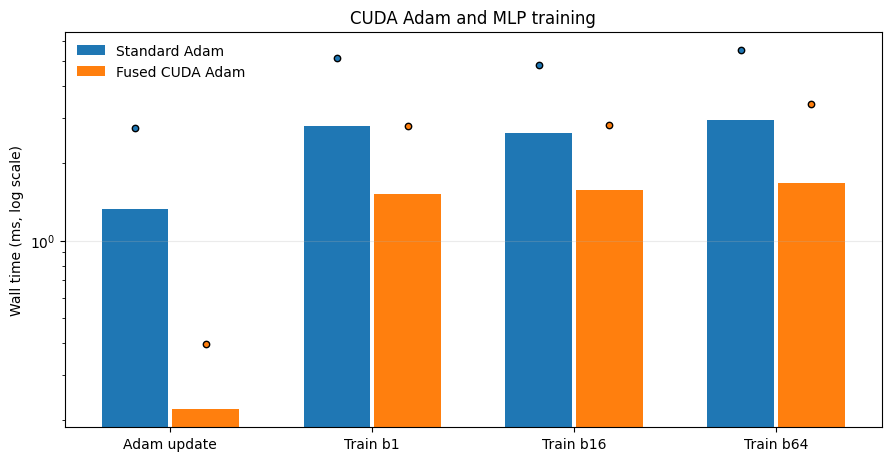

Standard → fused. Values are P50 / P95 in ms.
Adam update  1.328 / 2.756 → 0.220 / 0.396   (6.03× P50 speedup)
Train b1     2.794 / 5.156 → 1.527 / 2.799   (1.83× P50 speedup)
Train b16    2.629 / 4.852 → 1.577 / 2.834   (1.67× P50 speedup)
Train b64    2.946 / 5.558 → 1.674 / 3.425   (1.76× P50 speedup)


In [4]:
names = ('Adam update', *(f'Train b{size}' for size in BATCHES))
positions = np.arange(len(names))
fig, ax = plt.subplots(figsize=(8.8, 4.5), layout='constrained')
for index, label in enumerate(('Standard Adam', 'Fused CUDA Adam')):
    p50, p95 = np.array([results[name][index] for name in names]).T
    centers = positions + (index - 0.5) * 0.35
    bars = ax.bar(centers, p50, 0.33, label=label)
    ax.scatter(centers, p95, color=bars[0].get_facecolor(), edgecolor='black', s=21)
ax.set(title='CUDA Adam and MLP training', ylabel='Wall time (ms, log scale)', yscale='log')
ax.set_xticks(positions, names)
ax.legend(frameon=False)
ax.grid(axis='y', alpha=0.25)
plt.show()

print('Standard → fused. Values are P50 / P95 in ms.')
for name in names:
    (old_50, old_95), (new_50, new_95) = results[name]
    print(f'{name:<12} {old_50:.3f} / {old_95:.3f} → {new_50:.3f} / {new_95:.3f}'
          f'   ({old_50 / new_50:.2f}× P50 speedup)')

## Results from the saved run

The isolated Adam update took **1.328 ms** with standard CUDA Adam and
**0.220 ms** with fusion, a **6.03×** P50 speedup. The MLP training step
improved **1.67–1.83×** across batches 1, 16, and 64. Losses, gradients,
weights, moment estimates, and step counts agreed across the twelve checked
updates per batch size.

Bars show P50 and dots show P95. The optimizer-only result isolates launches
and array operations. Full training also includes pre-existing forward and
backward kernels, so its speedup depends on the fraction of time spent in Adam.
These timings cover the tested hardware, FP32 MLP, and batch sizes.